# Layer stacks as transfer functions: Goos-Hänchen shift, frustrated TIR and etalons

`thin_films.r_t_coeffs()` gives the reflection and transmission coefficients
of a layer stack for one plane wave. A beam is a superposition of plane
waves $\exp(i(k_x x + k_y y + k_z z))$, and each of them hits the stack under
its own angle, $\sin\theta_0 = \lvert\mathbf{k}_\perp\rvert/(k_0 n_0)$.
`thin_films.stack_transfer_functions()` evaluates $r$ and $t$ on the frequency
grid of a field, so that

$$ E_r = \mathcal{F}^{-1}\bigl[r\,\mathcal{F}[E_i]\bigr], \qquad E_t = \mathcal{F}^{-1}\bigl[t\,\mathcal{F}[E_i]\bigr], $$

with $E_i$ and $E_r$ at the top of the stack and $E_t$ at its bottom. This is a
scalar model: the field is a tangential component of $\mathbf{E}$, and all
plane waves are treated as s (TE) or p (TM) polarized. It is exact for
fields that vary only along $x$ (here: beams in the plane of incidence $x$-$z$,
uniform along $y$) and a good approximation for narrow angular spectra.

**Convention:** $\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$; lengths in units of
the vacuum wavelength unless stated otherwise.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics.fft import FT, inv_FT
from pyoptics.thin_films import stack_transfer_functions, r_t_coeffs
from pyoptics.utils import grid1d, grid2d, freq_grid

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

# 1D beams in the plane of incidence: many samples along x, two along y
wl = 1.0
k0 = 2*np.pi/wl
x = grid1d(-400, 400, 8192)
y = grid1d(-1, 1, 2)
X, Y = np.meshgrid(x, y)
row = 1                                   # the row with k_y = 0
k_x = freq_grid(x, y)[0][row]

def tilted_gaussian(w, theta, n):
    """Gaussian beam (waist w in the plane z = 0) incident under theta in a medium n."""
    return np.exp(-X**2/w**2)*np.exp(1j*k0*n*np.sin(theta)*X)

## 1. Total internal reflection: the phase of $r$

At a glass–air interface ($n_1 = 1.5$, critical angle 41.8°) $\lvert r\rvert = 1$ beyond the
critical angle, but the phase of $r$ changes with the angle, differently for s
and p. Plotted against $\sin\theta_0 = k_x/(k_0 n_1)$ straight from the transfer
function:

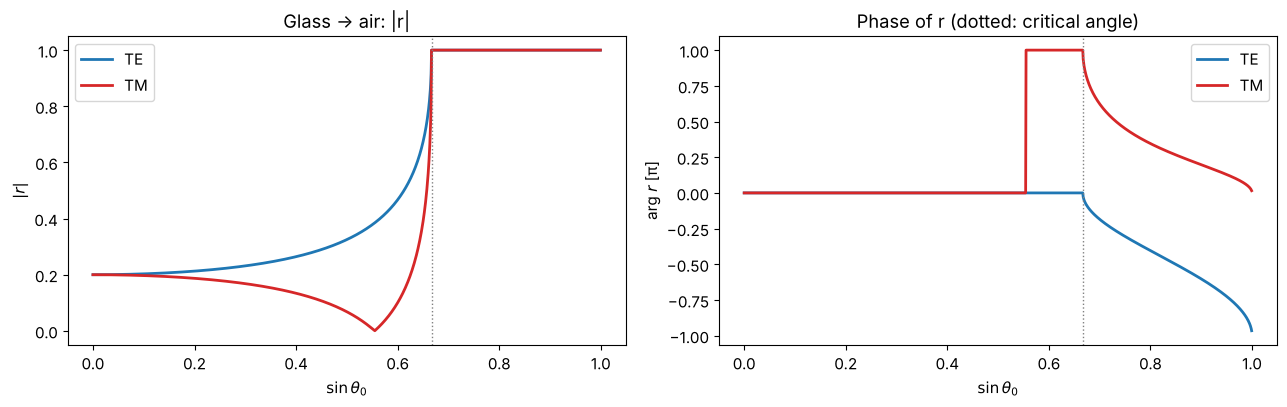

In [2]:
n1, n2 = 1.5, 1.0
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
s = k_x/(k0*n1)
sel = (s >= 0) & (s < 1)
for pol, color in (("TE", "C0"), ("TM", "C3")):
    r, _ = stack_transfer_functions(x, y, [], [], [], n1, 0.0, n2, 0.0, pol, wl)
    axes[0].plot(s[sel], np.abs(r[row, sel]), color=color, lw=2, label=pol)
    axes[1].plot(s[sel], np.angle(r[row, sel])/np.pi, color=color, lw=2, label=pol)
for ax in axes:
    ax.axvline(n2/n1, color="gray", ls=":", lw=1)
    ax.set_xlabel("$\\sin\\theta_0$")
axes[0].set_ylabel("$|r|$"); axes[1].set_ylabel("arg $r$ [π]")
axes[0].set_title("Glass → air: |r|"); axes[1].set_title("Phase of r (dotted: critical angle)")
axes[0].legend(); axes[1].legend()
fig.tight_layout()

## 2. The Goos-Hänchen shift

A phase of $r$ that depends on $k_x$ is a shift in $x$: if $r = e^{i\phi(k_x)}$, the
reflected beam is displaced along the interface by $D = -\partial\phi/\partial k_x$
(for $\exp(+ik_x x)$ and the forward FT kernel $\exp(-ik_x x)$). Artmann's result for
beams much wider than the wavelength is

$$ D_s = \frac{2\tan\theta}{k_1\sqrt{\sin^2\theta - n^2}}, \qquad D_p = D_s\,\frac{n^2}{(1+n^2)\sin^2\theta - n^2}, \qquad n = n_2/n_1, $$

a shift of the order of a wavelength **in the direction of propagation** along
the interface. The beam behaves as if it entered the optically thinner medium
and were reflected slightly behind the interface.

Below, Gaussian beams with waists of 10 and 40 wavelengths are totally
reflected; the shift is the displacement of the centroid of $\lvert E_r\rvert^2$.

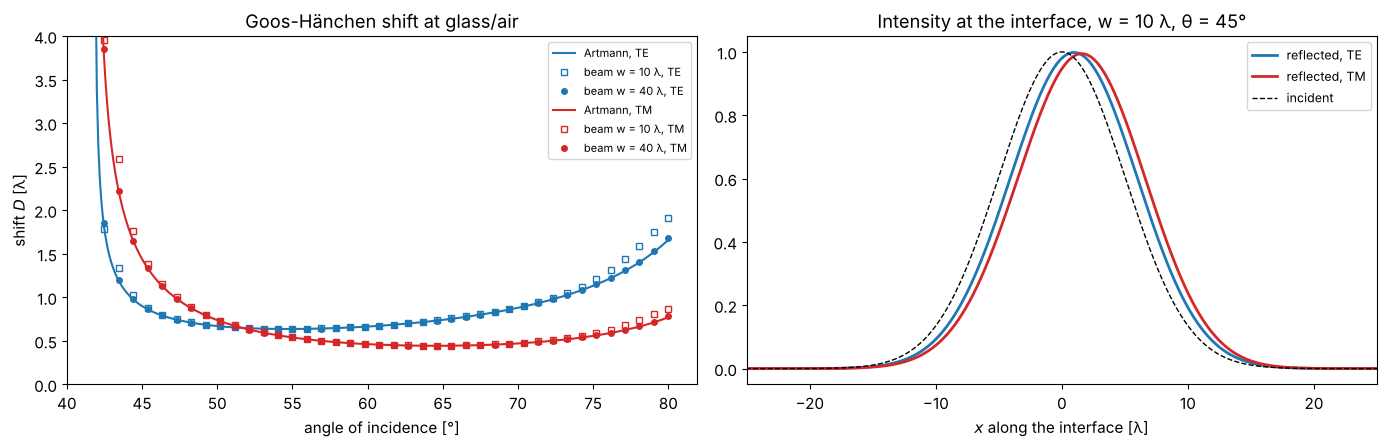

In [3]:
theta_c = np.arcsin(n2/n1)
thetas = np.deg2rad(np.linspace(42.5, 80, 40))
theta_fine = np.deg2rad(np.linspace(41.9, 80, 400))
n = n2/n1
q = np.sqrt(np.sin(theta_fine)**2 - n**2)
D_s = 2*np.tan(theta_fine)/(k0*n1*q)
D_p = D_s*n**2/((1 + n**2)*np.sin(theta_fine)**2 - n**2)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for pol, D, color in (("TE", D_s, "C0"), ("TM", D_p, "C3")):
    r, _ = stack_transfer_functions(x, y, [], [], [], n1, 0.0, n2, 0.0, pol, wl)
    axes[0].plot(np.rad2deg(theta_fine), D, "-", color=color, lw=1.5, label=f"Artmann, {pol}")
    for w, marker in ((10.0, "s"), (40.0, "o")):
        shifts = []
        for theta in thetas:
            E_r = inv_FT(r*FT(tilted_gaussian(w, theta, n1)))
            I_r = np.abs(E_r[row])**2
            shifts.append(np.sum(x*I_r)/np.sum(I_r))
        axes[0].plot(np.rad2deg(thetas), shifts, marker, color=color, ms=4, mfc="none" if w == 10 else color,
                     label=f"beam w = {w:.0f} λ, {pol}")
axes[0].set_ylim(0, 4); axes[0].set_xlabel("angle of incidence [°]"); axes[0].set_ylabel("shift $D$ [λ]")
axes[0].set_title("Goos-Hänchen shift at glass/air"); axes[0].legend(fontsize=8)

theta = np.deg2rad(45.0)
E_i = tilted_gaussian(10.0, theta, n1)
for pol, color in (("TE", "C0"), ("TM", "C3")):
    r, _ = stack_transfer_functions(x, y, [], [], [], n1, 0.0, n2, 0.0, pol, wl)
    axes[1].plot(x, np.abs(inv_FT(r*FT(E_i))[row])**2, color=color, lw=2, label=f"reflected, {pol}")
axes[1].plot(x, np.abs(E_i[row])**2, "k--", lw=1, label="incident")
axes[1].set_xlim(-25, 25); axes[1].set_xlabel("$x$ along the interface [λ]")
axes[1].set_title("Intensity at the interface, w = 10 λ, θ = 45°"); axes[1].legend(fontsize=9)
fig.tight_layout()

Away from the critical angle the shifts follow Artmann's formula. Near the
critical angle p is shifted more than s (up to 51.7° here), at grazing
incidence less. Close to it the formula
diverges, but a real beam has a spread of angles, part of which is not
totally reflected; its shift stays finite and the narrower beam deviates
earlier. The shift is small compared to the beam, which is why it took
until 1947 and multiple reflections to measure it.

## 3. Frustrated total internal reflection

If a second glass block approaches the first one, the evanescent wave in the
air gap reaches it and part of the light tunnels through. For s polarization
the problem is identical to a quantum mechanical barrier,

$$ T = \left[1 + \frac{(k_z^2 + \kappa^2)^2}{4k_z^2\kappa^2}\,\sinh^2(\kappa d)\right]^{-1}, \qquad k_z = k_0 n_1\cos\theta, \quad \kappa = k_0\sqrt{n_1^2\sin^2\theta - 1}. $$

The gap is a layer of air between glass "embedding medium" and glass
"substrate". For a beam, the transmitted power is the sum over its plane wave
components.

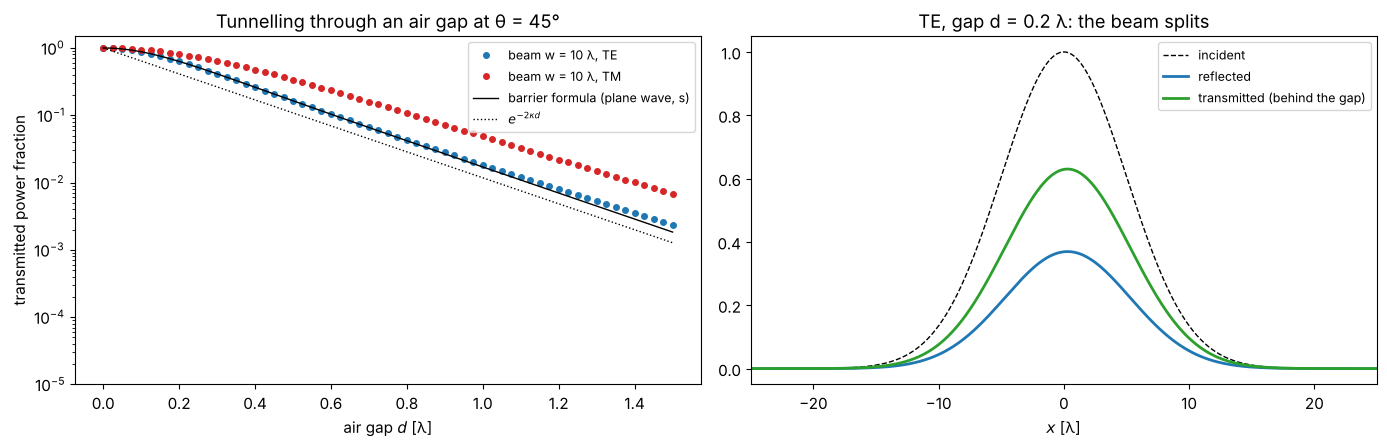

In [4]:
theta = np.deg2rad(45.0)
gaps = np.linspace(0, 1.5, 61)
E_i = tilted_gaussian(10.0, theta, n1)
S_i = np.abs(FT(E_i)[row])**2

kz = k0*n1*np.cos(theta)
kappa = k0*np.sqrt(n1**2*np.sin(theta)**2 - 1)
T_barrier = 1/(1 + (kz**2 + kappa**2)**2/(4*kz**2*kappa**2)*np.sinh(kappa*gaps)**2)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for pol, color in (("TE", "C0"), ("TM", "C3")):
    T_beam = []
    for d in gaps:
        _, t = stack_transfer_functions(x, y, [1.0], [0.0], [d], n1, 0.0, n1, 0.0, pol, wl)
        T_beam.append(np.sum(np.abs(t[row])**2*S_i)/np.sum(S_i))
    axes[0].semilogy(gaps, T_beam, "o", color=color, ms=4, label=f"beam w = 10 λ, {pol}")
axes[0].semilogy(gaps, T_barrier, "k-", lw=1, label="barrier formula (plane wave, s)")
axes[0].semilogy(gaps, np.exp(-2*kappa*gaps), "k:", lw=1, label="$e^{-2\\kappa d}$")
axes[0].set_xlabel("air gap $d$ [λ]"); axes[0].set_ylabel("transmitted power fraction")
axes[0].set_ylim(1E-5, 1.5); axes[0].set_title("Tunnelling through an air gap at θ = 45°")
axes[0].legend(fontsize=9)

d = 0.2
r, t = stack_transfer_functions(x, y, [1.0], [0.0], [d], n1, 0.0, n1, 0.0, "TE", wl)
axes[1].plot(x, np.abs(E_i[row])**2, "k--", lw=1, label="incident")
axes[1].plot(x, np.abs(inv_FT(r*FT(E_i))[row])**2, "C0", lw=2, label="reflected")
axes[1].plot(x, np.abs(inv_FT(t*FT(E_i))[row])**2, "C2", lw=2, label="transmitted (behind the gap)")
axes[1].set_xlim(-25, 25); axes[1].set_xlabel("$x$ [λ]")
axes[1].set_title(f"TE, gap d = {d} λ: the beam splits"); axes[1].legend(fontsize=9)
fig.tight_layout()

The decay length $1/(2\kappa)$ of the transmitted power is about 0.14 λ here:
a gap of one wavelength already blocks almost everything. Beam splitter
cubes and prism couplers use this effect with gaps adjusted to a fraction of
a wavelength.

## 4. A focused beam on a Fabry-Perot etalon

An etalon (two silver mirrors of 35 nm with a 20 µm silica spacer, at
λ = 633 nm) transmits only near the angles where the round trip phase is a
multiple of $2\pi$, i.e. where $2 n d\cos\theta_s = m\lambda$ in the spacer. Its transfer function $\lvert t(k_x, k_y)\rvert^2$ is therefore a set
of rings, the Haidinger fringes. A collimated beam can be tuned onto a
transmission peak, but a *focused* beam has a spread of angles, and only a
part of its angular spectrum fits through the ring. This is a full 2D
computation (unpolarized beams treated as s polarized, which is accurate for
the small angles involved).

resonant spacer thickness: 20.1533 µm, peak transmittance 0.575


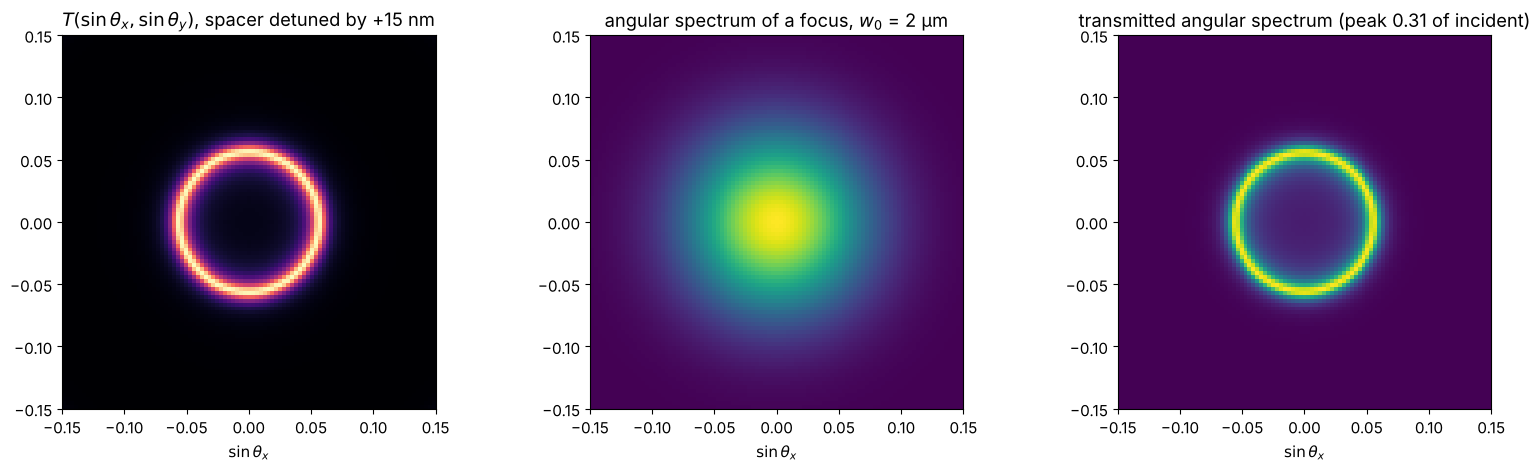

In [5]:
wl_um = 0.633
k0_um = 2*np.pi/wl_um
n_ag, k_ag, t_ag = 0.056, 4.28, 0.035      # silver at 633 nm, mirror thickness in µm
n_spacer = 1.457

def etalon(d_spacer):
    return ([n_ag, n_spacer, n_ag], [k_ag, 0.0, k_ag], [t_ag, d_spacer, t_ag])

def T_plane(d_spacer):
    """Plane wave transmittance at normal incidence (air -> etalon -> glass)."""
    n, k, t = etalon(d_spacer)
    _, t_coeff = r_t_coeffs(0.0, n, k, t, 1.0, 0.0, 1.5, 0.0, "TE", wl_um)
    return 1.5*np.abs(t_coeff)**2

# tune the spacer to a transmission maximum near 20 µm:
d_scan = 20.0 + np.linspace(0, wl_um/(2*n_spacer), 2001)
d_res = d_scan[np.argmax([T_plane(d) for d in d_scan])]
print(f"resonant spacer thickness: {d_res:.4f} µm, peak transmittance {T_plane(d_res):.3f}")

xs, ys, Xs, Ys = grid2d(-100, 100, -100, 100, 512)
KX, KY = freq_grid(xs, ys)
sin_theta = np.hypot(KX, KY)/k0_um
cos_theta = np.sqrt(np.clip(1 - sin_theta**2, 0, None))
cos_glass = np.sqrt(1 - (sin_theta/1.5)**2)
propagating = sin_theta < 1

def transmittance_map(d_spacer):
    _, t = stack_transfer_functions(xs, ys, *etalon(d_spacer), 1.0, 0.0, 1.5, 0.0, "TE", wl_um)
    # power transmittance per plane wave: |t|^2 n_s cos(theta_s)/(n_0 cos(theta_0))
    return np.where(propagating, np.abs(t)**2*1.5*cos_glass/np.where(propagating, cos_theta, 1), 0.0)

T_map = transmittance_map(d_res + 0.015)   # slightly detuned: a ring instead of a central spot
w0 = 2.0                                    # waist of the focused beam in µm
S_in = np.abs(FT(np.exp(-(Xs**2 + Ys**2)/w0**2)))**2
S_in /= S_in.max()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ext = np.array([KX.min(), KX.max(), KY.min(), KY.max()])/k0_um
lim = 0.15
axes[0].imshow(T_map, extent=ext, cmap="magma", vmin=0)
axes[0].set_title("$T(\\sin\\theta_x, \\sin\\theta_y)$, spacer detuned by +15 nm")
axes[1].imshow(S_in, extent=ext, cmap="viridis")
axes[1].set_title(f"angular spectrum of a focus, $w_0$ = {w0:.0f} µm")
axes[2].imshow(S_in*T_map, extent=ext, cmap="viridis", vmin=0)
axes[2].set_title(f"transmitted angular spectrum (peak {(S_in*T_map).max():.2f} of incident)")
for ax in axes:
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_xlabel("$\\sin\\theta_x$")
fig.tight_layout()

With the spacer 15 nm too thick, the normal incidence component is blocked
and only a thin ring of the focused beam's angular spectrum gets through: the
transmitted beam becomes a faint ring-shaped (Bessel-like) beam.

Tuning the spacer thickness through a resonance shows how much of a beam the
etalon can transmit. For a collimated (wide) beam the peak reaches the plane
wave value; the narrower the focus, the broader its angular spectrum and the
lower and wider the transmission peak, which also shifts to larger spacers
(the oblique components resonate at larger thickness, since the round trip
phase scales with $d\cos\theta$).

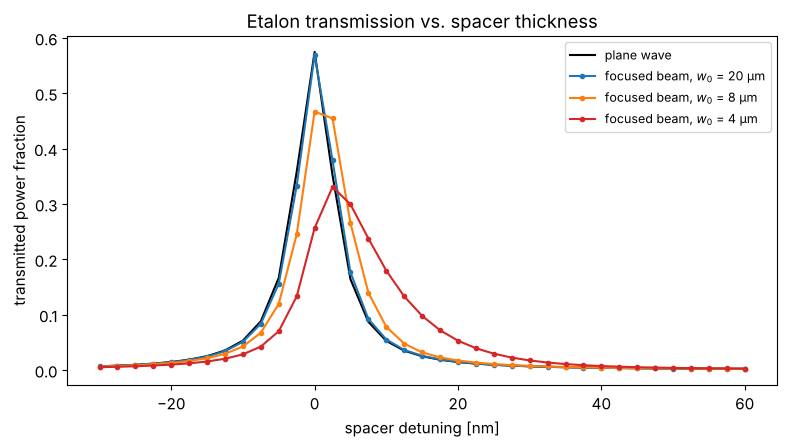

In [6]:
detunings = np.linspace(-0.03, 0.06, 37)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(1000*detunings, [T_plane(d_res + dd) for dd in detunings], "k-", lw=1.5, label="plane wave")
for w0, color in ((20.0, "C0"), (8.0, "C1"), (4.0, "C3")):
    S_in = np.abs(FT(np.exp(-(Xs**2 + Ys**2)/w0**2)))**2
    S_in /= S_in.sum()
    ax.plot(1000*detunings, [np.sum(S_in*transmittance_map(d_res + dd)) for dd in detunings], "o-", ms=3,
            color=color, label=f"focused beam, $w_0$ = {w0:.0f} µm")
ax.set_xlabel("spacer detuning [nm]"); ax.set_ylabel("transmitted power fraction")
ax.set_title("Etalon transmission vs. spacer thickness"); ax.legend(fontsize=9)
fig.tight_layout()